In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

import numpy as np
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical

In [ ]:
df1 = pd.read_csv('drive/MyDrive/Training_data/sas-sv_data.csv')



📊 THỐNG KÊ SỐ LƯỢNG NHÃN TRÊN TẬP df1 (Tổng: 184 mẫu)
    Nhãn mức độ  Số lượng mẫu  Tỷ lệ (%)
      L0 (Thấp)            22      11.96
L1 (Trung bình)            98      53.26
       L2 (Cao)            64      34.78


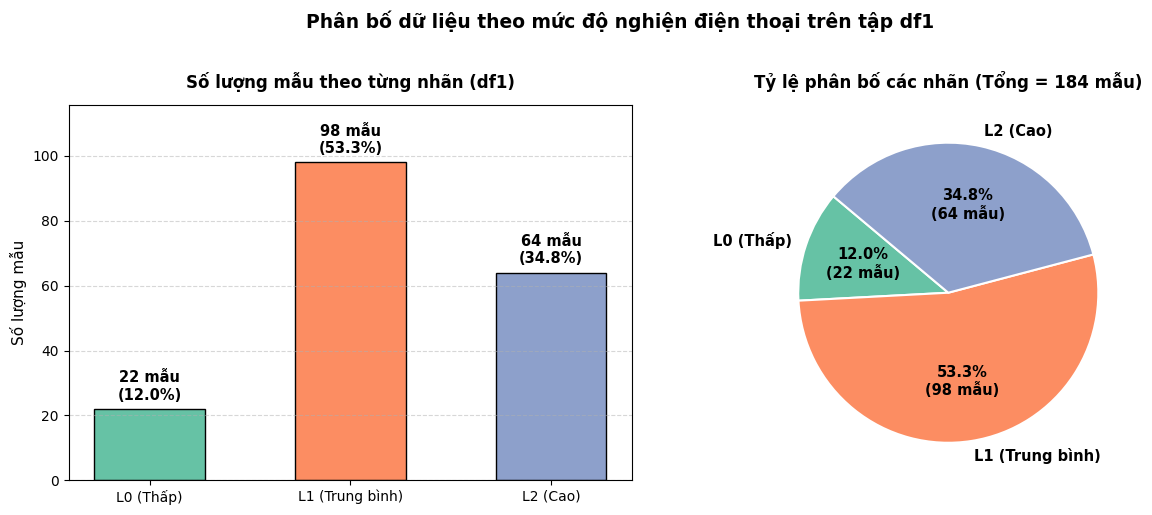

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =========================================================================
# 1. ĐỌC DỮ LIỆU df1 & CHUẨN HÓA CỘT NHÃN 'Level'
# =========================================================================
df1 = pd.read_csv('drive/MyDrive/Training_data/sas-sv_data.csv')
Y = df1['Level'].copy()

if Y.dtype == 'object' or Y.dtype.name == 'category':
    Y = Y.astype(str).str.strip().map({'L0': 0, 'L1': 1, 'L2': 2, '0': 0, '1': 1, '2': 2})
Y = pd.to_numeric(Y, errors='coerce').dropna().astype(int)
if len(Y) > 0 and Y.min() == 1:
    Y = Y - 1

# =========================================================================
# 2. THỐNG KÊ & IN SỐ LƯỢNG L0, L1, L2 TRÊN df1
# =========================================================================
label_names = ['L0 (Thấp)', 'L1 (Trung bình)', 'L2 (Cao)']
counts = [int((Y == i).sum()) for i in [0, 1, 2]]
total = sum(counts)
percentages = [(c / total * 100) if total > 0 else 0 for c in counts]

df_dist = pd.DataFrame({
    'Nhãn mức độ': label_names,
    'Số lượng mẫu': counts,
    'Tỷ lệ (%)': [round(p, 2) for p in percentages]
})

print("=" * 52)
print(f"📊 THỐNG KÊ SỐ LƯỢNG NHÃN TRÊN TẬP df1 (Tổng: {total} mẫu)")
print("=" * 52)
print(df_dist.to_string(index=False))
print("=" * 52)

# =========================================================================
# 3. VẼ BIỂU ĐỒ PHÂN BỐ SỐ LƯỢNG & TỶ LỆ L0, L1, L2
# =========================================================================
colors = ['#66c2a5', '#fc8d62', '#8da0cb']
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))

# Biểu đồ cột (số lượng + phần trăm)
bars = axes[0].bar(label_names, counts, color=colors, edgecolor='black', width=0.55)
for bar, count, pct in zip(bars, counts, percentages):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(counts) * 0.02,
        f"{count} mẫu\n({pct:.1f}%)",
        ha='center', va='bottom', fontsize=10.5, fontweight='bold'
    )
axes[0].set_title('Số lượng mẫu theo từng nhãn (df1)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_ylabel('Số lượng mẫu', fontsize=11)
axes[0].set_ylim(0, max(counts) * 1.18)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Biểu đồ tròn (tỷ lệ phần trăm)
axes[1].pie(
    counts,
    labels=label_names,
    autopct=lambda p: f'{p:.1f}%\n({int(round(p * total / 100))} mẫu)',
    startangle=140,
    colors=colors,
    textprops={'fontsize': 10.5, 'fontweight': 'bold'},
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
axes[1].set_title(f'Tỷ lệ phân bố các nhãn (Tổng = {total} mẫu)', fontsize=12, fontweight='bold', pad=12)

plt.suptitle('Phân bố dữ liệu theo mức độ nghiện điện thoại trên tập df1', fontsize=13.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('Phan_bo_L0_L1_L2_df1.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from imblearn.over_sampling import SMOTE

df1 = pd.read_csv('drive/MyDrive/Training_data/sas-sv_data.csv')

# ==========================================
# 1. TIỀN XỬ LÝ DỮ LIỆU TỪ df1
# ==========================================
df1 = df1.drop_duplicates().dropna()

# Xóa các cột ID hoặc cột điểm tổng gây rò rỉ dữ liệu
cols_to_drop = [col for col in ['ID', 'id', 'STT', 'Timestamp', 'Total_Score', 'Tong'] if col in df1.columns]
df1 = df1.drop(columns=cols_to_drop)

# Lấy chính xác cột nhãn 'Level'
target_col = 'Level' if 'Level' in df1.columns else ('Target' if 'Target' in df1.columns else df1.columns[-1])
X = df1.drop(columns=[target_col])
Y = df1[target_col]

# Mã hóa các cột dạng chữ/object trong X sang dạng số
X = pd.get_dummies(X, drop_first=True)

# Mã hóa Y sang số nguyên (0 -> L0, 1 -> L1, 2 -> L2)
if Y.dtype == 'object' or Y.dtype.name == 'category':
    Y = Y.astype(str).str.strip()
    le = LabelEncoder()
    Y = le.fit_transform(Y)
else:
    Y = Y.astype(int).values
    if Y.min() == 1:
        Y = Y - 1

# ==========================================
# 2. CHIA DỮ LIỆU: 70% Train - 15% Validation - 15% Test
# ==========================================
X_temp, X_test, y_temp, y_test = train_test_split(
    X, Y,
    test_size=0.15,
    random_state=42,
    stratify=Y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=(15 / 85),
    random_state=42,
    stratify=y_temp
)

# ==========================================
# 3. CHUẨN HÓA DỮ LIỆU (StandardScaler)
# ==========================================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# ==========================================
# 4. CÂN BẰNG LỚP TRÊN TẬP TRAIN BẰNG SMOTE
# ==========================================
sm = SMOTE(sampling_strategy='auto', random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train_scaled, y_train)

# ==========================================
# 5. IN KẾT QUẢ KIỂM TRA
# ==========================================
print(f"Cột mục tiêu (Y): {target_col} | Số đặc trưng (X): {X.shape[1]}")
print(f"✅ Tập Train gốc:           {X_train_scaled.shape[0]} mẫu")
print(f"✅ Tập Train sau khi SMOTE: {X_train_res.shape[0]} mẫu")
print(f"✅ Tập Validation:          {X_val_scaled.shape[0]} mẫu")
print(f"✅ Tập Test:                {X_test_scaled.shape[0]} mẫu")

Cột mục tiêu (Y): Level | Số đặc trưng (X): 15
✅ Tập Train gốc:           128 mẫu
✅ Tập Train sau khi SMOTE: 204 mẫu
✅ Tập Validation:          28 mẫu
✅ Tập Test:                28 mẫu


In [ ]:
import pandas as pd
import numpy as np

# Kiểm tra xem Cell 1 đã chạy chưa; nếu chưa thì báo rõ để chạy Cell 1 trước
required_vars = ['y_train', 'y_val', 'y_test', 'y_train_res']
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise RuntimeError(f"⚠️ Bạn chưa chạy Cell 1! Hãy bấm chạy Cell 1 phía trên trước để tạo các biến: {missing_vars}")

# ==========================================
# 6. THỐNG KÊ SỐ LƯỢNG & TỶ LỆ L0, L1, L2 TRÊN TỪNG TẬP (70/15/15)
# ==========================================
def thong_ke_phan_bo(splits_dict):
    all_y = np.concatenate([np.asarray(y) for y in splits_dict.values()])
    unique_classes = sorted(np.unique(all_y))

    # Lấy tên nhãn chuẩn ('L0', 'L1', 'L2')
    if 'le' in globals() and hasattr(le, 'classes_') and len(le.classes_) == len(unique_classes):
        label_names = list(le.classes_)
    else:
        label_names = [f"L{int(c)}" for c in unique_classes]

    rows = []
    for name, y_data in splits_dict.items():
        y_arr = np.asarray(y_data)
        total = len(y_arr)
        row = {
            'Tập dữ liệu': name,
            'Tổng mẫu': total
        }
        for cls_val, lbl in zip(unique_classes, label_names):
            count = int(np.sum(y_arr == cls_val))
            pct = (count / total * 100) if total > 0 else 0.0
            row[f'{lbl} (Số lượng / Tỷ lệ)'] = f"{count} ({pct:.2f}%)"
        rows.append(row)

    return pd.DataFrame(rows)

df_phan_bo = thong_ke_phan_bo({
    'Tập Train gốc (70%)': y_train,
    'Tập Validation (15%)': y_val,
    'Tập Test (15%)': y_test,
    'Tập Train sau SMOTE': y_train_res
})

print("=" * 95)
print("📊 THỐNG KÊ SỐ LƯỢNG VÀ TỶ LỆ NHÃN L0, L1, L2 THEO TỶ LỆ CHIA 70/15/15")
print("=" * 95)
print(df_phan_bo.to_string(index=False))
print("=" * 95)

📊 THỐNG KÊ SỐ LƯỢNG VÀ TỶ LỆ NHÃN L0, L1, L2 THEO TỶ LỆ CHIA 70/15/15
         Tập dữ liệu  Tổng mẫu L0 (Số lượng / Tỷ lệ) L1 (Số lượng / Tỷ lệ) L2 (Số lượng / Tỷ lệ)
 Tập Train gốc (70%)       128           16 (12.50%)           68 (53.12%)           44 (34.38%)
Tập Validation (15%)        28            3 (10.71%)           15 (53.57%)           10 (35.71%)
      Tập Test (15%)        28            3 (10.71%)           15 (53.57%)           10 (35.71%)
 Tập Train sau SMOTE       204           68 (33.33%)           68 (33.33%)           68 (33.33%)


MÔ HÌNH XỬ LÍ SMOTE, IQR VÀ 2 TẦNG ẨN CÙNG RELU


In [ ]:
from collections import Counter
from imblearn.over_sampling import SMOTE

# 1. Xem số lượng mẫu của 3 nhóm L0, L1, L2 trước khi SMOTE
print("📊 Số lượng từng nhóm TRƯỚC khi SMOTE:", sorted(Counter(y_train).items()))

# 2. Áp dụng SMOTE cho bài toán đa lớp (Multi-class: L0, L1, L2)
# sampling_strategy='not majority' sẽ giữ nguyên nhóm đông nhất và tăng 2 nhóm ít hơn lên bằng nhóm đông nhất
sm = SMOTE(sampling_strategy='not majority', random_state=42, k_neighbors=5)
X_train_res, y_train_res = sm.fit_resample(X_train_scaled, y_train)

# 3. Kiểm tra lại số lượng 3 nhóm sau khi SMOTE
print("✅ Số lượng từng nhóm SAU khi SMOTE:  ", sorted(Counter(y_train_res).items()))

📊 Số lượng từng nhóm TRƯỚC khi SMOTE: [(0, 16), (1, 68), (2, 44)]
✅ Số lượng từng nhóm SAU khi SMOTE:   [(0, 68), (1, 68), (2, 68)]


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,683 (14.39 KB)

 Trainable params: 3,683 (14.39 KB)

 Non-trainable params: 0 (0.00 B)


--- Bắt đầu Huấn luyện Mô hình trên df1 ---
Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.4314 - loss: 1.0921 - val_accuracy: 0.6071 - val_loss: 0.9544
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.5049 - loss: 0.9682 - val_accuracy: 0.5714 - val_loss: 0.8827
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6912 - loss: 0.8065 - val_accuracy: 0.5357 - val_loss: 0.8143
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7010 - loss: 0.7404 - val_accuracy: 0.5357 - val_loss: 0.7462
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7549 - loss: 0.6782 - val_accuracy: 0.6429 - val_loss: 0.6909
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7598 - loss: 0.5834 - val_accuracy: 0.6786 - val_loss: 0.6552
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7549 - loss: 0.5610 - val_accuracy: 0.7857 - val_loss: 0.6201
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0

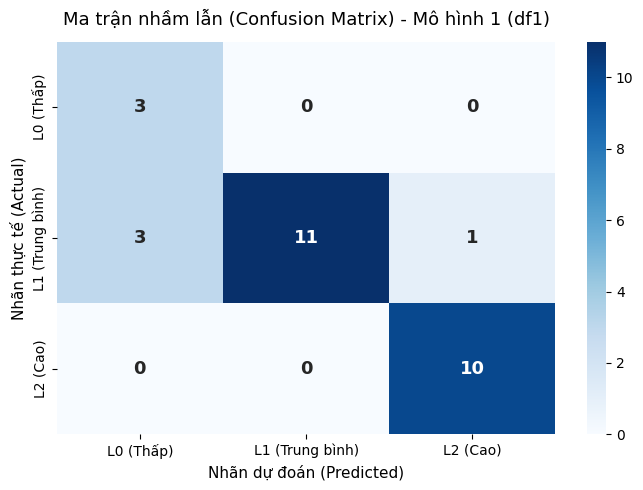

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from imblearn.over_sampling import SMOTE
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Đọc dữ liệu df1 từ Google Drive (bỏ qua dòng này nếu df1 đã có sẵn trong bộ nhớ)
df1 = pd.read_csv('drive/MyDrive/Training_data/sas-sv_data.csv')

# ==============================================================================
# 1. LÀM SẠCH SƠ BỘ & MÃ HÓA BIẾN PHÂN LOẠI TỪ df1
# ==============================================================================
data = df1.copy()

# Loại bỏ dòng thiếu nhãn 'Level'
data = data.dropna(subset=['Level'])

# Chuẩn hóa nhãn 'Level' về số nguyên 0, 1, 2... (an toàn cho to_categorical)
if data['Level'].dtype == 'object' or data['Level'].dtype.name == 'category':
    le = LabelEncoder()
    Y = pd.Series(le.fit_transform(data['Level']), index=data.index)
else:
    Y = data['Level'].astype(int)
    if Y.min() == 1:  # Nếu nhãn gốc đánh số 1, 2, 3 thì dịch về 0, 1, 2
        Y = Y - 1

# Loại bỏ các cột không dùng làm đặc trưng hoặc gây rò rỉ dữ liệu
cols_to_drop = ['ID', 'id', 'STT', 'name', 'rating', 'created_at', 'addiction', 'Total_Score', 'Level']
existing_cols_to_drop = [col for col in cols_to_drop if col in data.columns]
X = data.drop(columns=existing_cols_to_drop)

# Mã hóa toàn bộ các biến phân loại dạng chữ (Truong, Khoi, Phai, Gender...)
X_encoded = pd.get_dummies(X, drop_first=True)

# Ép kiểu toàn bộ về dạng số (chưa điền NaN vội để tránh rò rỉ dữ liệu)
X_encoded = X_encoded.apply(pd.to_numeric, errors='coerce')

# ==============================================================================
# 2. CHIA TẬP DỮ LIỆU: 70% TRAIN - 15% VALIDATION - 15% TEST (CHIA TRƯỚC KHI SMOTE)
# ==============================================================================
X_temp, X_test, Y_temp, Y_test = train_test_split(
    X_encoded, Y, test_size=0.15, random_state=42, stratify=Y
)

X_train, X_val, Y_train, Y_val = train_test_split(
    X_temp, Y_temp, test_size=(15 / 85), random_state=42, stratify=Y_temp
)

# ==============================================================================
# 3. XỬ LÝ NGOẠI LAI (CAPPING), ĐIỀN KHUYẾT & CHUẨN HÓA (CHỈ FIT TRÊN TRAIN)
# ==============================================================================
# A. Điền giá trị trống bằng trung vị (median) tính từ tập Train (+ fillna(0) dự phòng)
train_medians = X_train.median()
X_train = X_train.fillna(train_medians).fillna(0)
X_val = X_val.fillna(train_medians).fillna(0)
X_test = X_test.fillna(train_medians).fillna(0)

# B. Xử lý ngoại lai (Capping) cho 'tg_sudung_dt' theo ngưỡng của tập Train
feature_outlier = 'tg_sudung_dt'
if feature_outlier in X_train.columns:
    Q1 = X_train[feature_outlier].quantile(0.25)
    Q3 = X_train[feature_outlier].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR

    X_train[feature_outlier] = np.minimum(X_train[feature_outlier], upper_bound)
    X_val[feature_outlier] = np.minimum(X_val[feature_outlier], upper_bound)
    X_test[feature_outlier] = np.minimum(X_test[feature_outlier], upper_bound)

# C. Chuẩn hóa dữ liệu (StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# ==============================================================================
# 4. CÂN BẰNG LỚP BẰNG SMOTE (CHỈ ÁP DỤNG TRÊN TẬP TRAIN)
# ==============================================================================
sm = SMOTE(sampling_strategy='auto', random_state=42)
X_train_res, Y_train_res = sm.fit_resample(X_train_scaled, Y_train)

# Mã hóa One-Hot cho biến mục tiêu Y
num_classes = len(np.unique(Y))
Y_train_oh = to_categorical(Y_train_res, num_classes=num_classes)
Y_val_oh = to_categorical(Y_val, num_classes=num_classes)
Y_test_oh = to_categorical(Y_test, num_classes=num_classes)

# ==============================================================================
# 5. XÂY DỰNG & HUẤN LUYỆN MẠNG NƠ-RON
# ==============================================================================
tf.random.set_seed(42)
input_dim = X_train_res.shape[1]

model = Sequential([
    Input(shape=(input_dim,)),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Tự động dừng sớm nếu Val Loss không cải thiện sau 20 epochs và khôi phục trọng số tốt nhất
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True
)

print("\n--- Bắt đầu Huấn luyện Mô hình trên df1 ---")
history = model.fit(
    X_train_res,
    Y_train_oh,
    epochs=300,
    batch_size=16,
    validation_data=(X_val_scaled, Y_val_oh),
    callbacks=[early_stop],
    verbose=1
)

# Đánh giá trên tập Test độc lập
test_loss, test_acc = model.evaluate(X_test_scaled, Y_test_oh, verbose=0)
print(f"\n✅ Huấn luyện hoàn tất | Độ chính xác trên tập Test thực tế: {test_acc * 100:.2f}%")

# ==============================================================================
# 6. BÁO CÁO ĐÁNH GIÁ & MA TRẬN NHẦM LẪN
# ==============================================================================
Y_pred_prob = model.predict(X_test_scaled)
Y_pred = np.argmax(Y_pred_prob, axis=1)
Y_true = np.argmax(Y_test, axis=1) if len(np.shape(Y_test)) > 1 else Y_test

labels = ['L0 (Thấp)', 'L1 (Trung bình)', 'L2 (Cao)'] if num_classes == 3 else [f'L{i}' for i in range(num_classes)]
print("=== BÁO CÁO ĐÁNH GIÁ MÔ HÌNH 1 (df1) ===")
print(classification_report(Y_true, Y_pred, target_names=labels, digits=4))

cm = confusion_matrix(Y_true, Y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=labels,
    yticklabels=labels,
    annot_kws={"size": 13, "weight": "bold"}
)
plt.title('Ma trận nhầm lẫn (Confusion Matrix) - Mô hình 1 (df1)', fontsize=13, pad=12)
plt.xlabel('Nhãn dự đoán (Predicted)', fontsize=11)
plt.ylabel('Nhãn thực tế (Actual)', fontsize=11)
plt.tight_layout()
plt.show()

XÁC ĐỊNH HỆ SỐ TƯƠNG QUAN CỦA 14 ĐẶC TRƯNG

=== BẢNG HỆ SỐ TƯƠNG QUAN VỚI MỨC ĐỘ NGHIỆN ĐIỆN THOẠI (LEVEL) ===
   Đặc trưng  Spearman (rho)  Pearson (r)  p-value Ý nghĩa thống kê
      Q_MEAN          0.8431       0.8441   0.0000    Có (p < 0.05)
       Q_MAX          0.7065       0.7102   0.0000    Có (p < 0.05)
          Q9          0.7059       0.6972   0.0000    Có (p < 0.05)
          Q7          0.6706       0.6734   0.0000    Có (p < 0.05)
         Q10          0.6292       0.6390   0.0000    Có (p < 0.05)
          Q8          0.6281       0.6350   0.0000    Có (p < 0.05)
          Q4          0.6003       0.6175   0.0000    Có (p < 0.05)
          Q5          0.5854       0.6012   0.0000    Có (p < 0.05)
          Q6          0.5038       0.5310   0.0000    Có (p < 0.05)
          Q2          0.4776       0.5124   0.0000    Có (p < 0.05)
          Q3          0.4678       0.4833   0.0000    Có (p < 0.05)
          Q1          0.4252       0.4646   0.0000    Có (p < 0.05)
       Q_STD          0.3987       0.4203   0.000

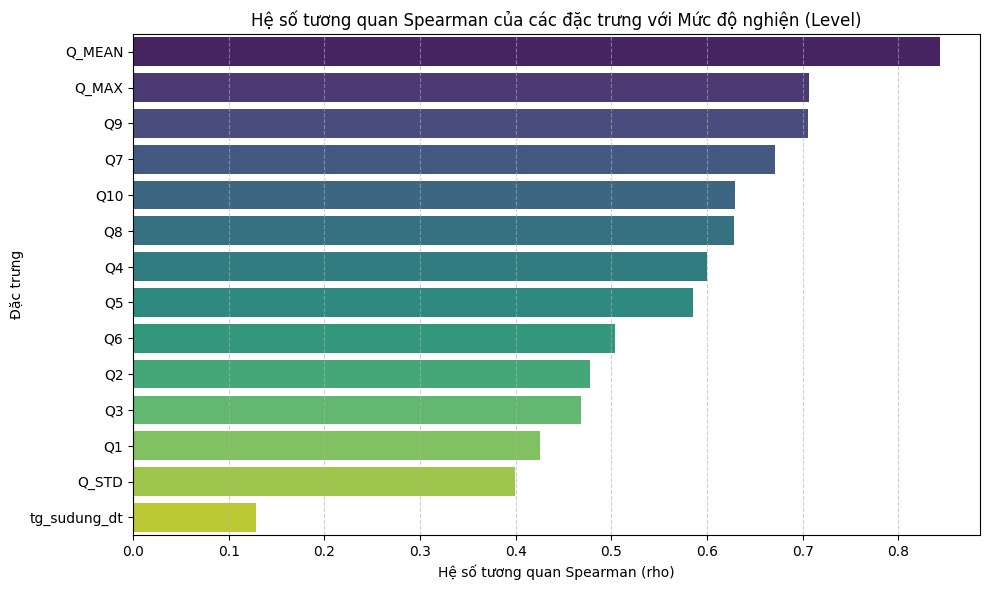

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

# 1. Tạo bản sao dữ liệu và chuẩn hóa kiểu số
data_corr = df.copy()

q_cols = ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10']
base_features = ['tg_sudung_dt'] + q_cols

for col in base_features:
    if col in data_corr.columns:
        data_corr[col] = pd.to_numeric(data_corr[col], errors='coerce')

# Đảm bảo cột 'Level' ở dạng số (hỗ trợ cả trường hợp nhãn là 'L0', 'L1', 'L2')
if data_corr['Level'].dtype == 'object':
    level_map = {'L0': 0, 'L1': 1, 'L2': 2}
    data_corr['Level'] = data_corr['Level'].map(level_map).fillna(data_corr['Level'])
data_corr['Level'] = pd.to_numeric(data_corr['Level'], errors='coerce')

# 2. Tính toán 3 đặc trưng thống kê trên hàng ngang (axis=1) từ Q1 đến Q10
data_corr['Q_MAX'] = data_corr[q_cols].max(axis=1)
data_corr['Q_STD'] = data_corr[q_cols].std(axis=1)
data_corr['Q_MEAN'] = data_corr[q_cols].mean(axis=1)

all_features = ['tg_sudung_dt'] + q_cols + ['Q_MAX', 'Q_STD', 'Q_MEAN']

# Loại bỏ các dòng có giá trị rỗng để tính tương quan chính xác
df_clean = data_corr[all_features + ['Level']].dropna()

# 3. Tính hệ số tương quan Pearson & Spearman kèm p-value
results = []
for feat in all_features:
    r_pearson, p_pearson = pearsonr(df_clean[feat], df_clean['Level'])
    r_spearman, p_spearman = spearmanr(df_clean[feat], df_clean['Level'])

    results.append({
        'Đặc trưng': feat,
        'Spearman (rho)': round(r_spearman, 4),
        'Pearson (r)': round(r_pearson, 4),
        'p-value': round(p_spearman, 4),
        'Ý nghĩa thống kê': 'Có (p < 0.05)' if p_spearman < 0.05 else 'Không'
    })

# Sắp xếp giảm dần theo độ mạnh tương quan Spearman
corr_df = pd.DataFrame(results).sort_values(by='Spearman (rho)', ascending=False)

print("=== BẢNG HỆ SỐ TƯƠNG QUAN VỚI MỨC ĐỘ NGHIỆN ĐIỆN THOẠI (LEVEL) ===")
print(corr_df.to_string(index=False))

# 4. Vẽ biểu đồ cột ngang xếp hạng mức độ tương quan
plt.figure(figsize=(10, 6))
sns.barplot(
    data=corr_df,
    x='Spearman (rho)',
    y='Đặc trưng',
    hue='Đặc trưng',
    palette='viridis',
    legend=False
)
plt.title('Hệ số tương quan Spearman của các đặc trưng với Mức độ nghiện (Level)', fontsize=12)
plt.xlabel('Hệ số tương quan Spearman (rho)')
plt.ylabel('Đặc trưng')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

HUẤN LUYỆN 10-FOLD CROSS-VALIDATION, 3 TẦNG ẨN VÀ HÀM MISH

In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns

# =========================================================================
# ĐẶT MÃ CHIA TẬP DỮ LIỆU TẠI ĐÂY (PHẢI GIỐNG HỆT Ở CELL SO SÁNH BÊN DƯỚI)
# =========================================================================
SPLIT_SEED = 7
SAVED_SPLIT_SEED = SPLIT_SEED

# =========================================================================
# 1. ĐỌC DỮ LIỆU & FEATURE ENGINEERING
# =========================================================================
df1 = pd.read_csv('drive/MyDrive/Training_data/sas-sv_data.csv')
df = df1.copy()
# Nếu muốn chạy trên tập gộp 507 mẫu, bỏ dấu # ở 2 dòng dưới:
# df2 = pd.read_csv('drive/MyDrive/Training_data/Smartphone_addiction_2.csv')
# df = pd.concat([df1, df2], ignore_index=True)

selected_features = ['tg_sudung_dt', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10']
valid_features = [col for col in selected_features if col in df.columns]

X_original = df[valid_features].copy()
Y = df['Level'].copy()

if Y.dtype == 'object':
    Y = Y.astype(str).str.strip().map({'L0': 0, 'L1': 1, 'L2': 2, '0': 0, '1': 1, '2': 2})
Y = pd.to_numeric(Y, errors='coerce')

valid_idx = Y.notna()
X_original = X_original[valid_idx].apply(pd.to_numeric, errors='coerce')
Y = Y[valid_idx].astype(int)

q_cols = [c for c in ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10'] if c in X_original.columns]
if len(q_cols) > 0:
    X_original['Q_mean'] = X_original[q_cols].mean(axis=1)
    X_original['Q_std']  = X_original[q_cols].std(axis=1)
    X_original['Q_max']  = X_original[q_cols].max(axis=1)

# =========================================================================
# 2. TÁCH TẬP TEST ĐỘC LẬP 15% THEO SPLIT_SEED
# =========================================================================
X_train_raw, X_test_raw, Y_train_raw, Y_test_raw = train_test_split(
    X_original, Y, test_size=0.15, random_state=SPLIT_SEED, stratify=Y
)

# =========================================================================
# 3. KIẾN TRÚC MẠNG FNN TỐI ƯU (MISH + BATCHNORM + DROPOUT)
# =========================================================================
def create_optimized_fnn(input_dim, output_classes):
    model = Sequential([
        Input(shape=(input_dim,)),

        Dense(128, activation='mish'),
        BatchNormalization(),
        Dropout(0.2),

        Dense(64, activation='mish'),
        BatchNormalization(),
        Dropout(0.15),

        Dense(32, activation='mish'),
        BatchNormalization(),
        Dropout(0.1),

        Dense(output_classes, activation='softmax')
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model
# =========================================================================
# 4. HUẤN LUYỆN 10-FOLD ENSEMBLE FNN
# =========================================================================
n_splits = 10
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SPLIT_SEED)

output_classes = len(np.unique(Y))
test_predictions_folds = np.zeros((len(X_test_raw), output_classes))
oof_predictions = np.zeros((len(X_train_raw), output_classes))

print(f"🚀 Huấn luyện {n_splits}-Fold FNN Ensemble ({len(Y)} mẫu | SPLIT_SEED={SPLIT_SEED})...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_raw, Y_train_raw), 1):
    tf.keras.backend.clear_session()
    tf.random.set_seed(SPLIT_SEED + fold)

    X_tr = X_train_raw.iloc[train_idx].copy()
    Y_tr = Y_train_raw.iloc[train_idx].copy()

    X_val = X_train_raw.iloc[val_idx].copy()
    Y_val = Y_train_raw.iloc[val_idx].copy()

    X_te = X_test_raw.copy()

    fold_medians = X_tr.median()
    X_tr = X_tr.fillna(fold_medians).fillna(0)
    X_val = X_val.fillna(fold_medians).fillna(0)
    X_te = X_te.fillna(fold_medians).fillna(0)

    feature_outlier = 'tg_sudung_dt'
    if feature_outlier in X_tr.columns:
        Q1 = X_tr[feature_outlier].quantile(0.25)
        Q3 = X_tr[feature_outlier].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        X_tr[feature_outlier] = np.clip(X_tr[feature_outlier], lower_bound, upper_bound)
        X_val[feature_outlier] = np.clip(X_val[feature_outlier], lower_bound, upper_bound)
        X_te[feature_outlier] = np.clip(X_te[feature_outlier], lower_bound, upper_bound)

    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_val_scaled = scaler.transform(X_val)
    X_te_scaled = scaler.transform(X_te)

    sm = SMOTE(sampling_strategy='auto', random_state=SPLIT_SEED + fold)
    X_tr_res, Y_tr_res = sm.fit_resample(X_tr_scaled, Y_tr)

    Y_tr_one_hot = to_categorical(Y_tr_res, num_classes=output_classes)
    Y_val_one_hot = to_categorical(Y_val, num_classes=output_classes)

    callbacks = [
        EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7, min_lr=1e-5, verbose=0)
    ]

    model = create_optimized_fnn(input_dim=X_tr_res.shape[1], output_classes=output_classes)

    model.fit(
        X_tr_res, Y_tr_one_hot,
        epochs=200,
        batch_size=16,
        validation_data=(X_val_scaled, Y_val_one_hot),
        callbacks=callbacks,
        verbose=0
    )

    val_pred_prob = model.predict(X_val_scaled, verbose=0)
    oof_predictions[val_idx] = val_pred_prob
    val_acc = accuracy_score(Y_val, np.argmax(val_pred_prob, axis=1))

    fold_test_pred_prob = model.predict(X_te_scaled, verbose=0)
    test_predictions_folds += fold_test_pred_prob / n_splits

    print(f"✅ Fold {fold:2d}/{n_splits} | Val Acc: {val_acc * 100:.2f}%")

oof_accuracy = accuracy_score(Y_train_raw, np.argmax(oof_predictions, axis=1))
Y_pred_class = np.argmax(test_predictions_folds, axis=1)
Y_test_class = Y_test_raw.values
test_accuracy = accuracy_score(Y_test_class, Y_pred_class)

print("\n" + "=" * 60)
print(f"📊 OOF Val Accuracy:  {oof_accuracy * 100:.2f}%")
print(f"🎯 Test Accuracy 15%: {test_accuracy * 100:.2f}%")
print("=" * 60)

🚀 Huấn luyện 10-Fold FNN Ensemble (184 mẫu | SPLIT_SEED=7)...
✅ Fold  1/10 | Val Acc: 93.75%
✅ Fold  2/10 | Val Acc: 100.00%
✅ Fold  3/10 | Val Acc: 87.50%
✅ Fold  4/10 | Val Acc: 81.25%
✅ Fold  5/10 | Val Acc: 100.00%
✅ Fold  6/10 | Val Acc: 93.75%
✅ Fold  7/10 | Val Acc: 100.00%
✅ Fold  8/10 | Val Acc: 86.67%
✅ Fold  9/10 | Val Acc: 93.33%
✅ Fold 10/10 | Val Acc: 93.33%

📊 OOF Val Accuracy:  92.95%
🎯 Test Accuracy 15%: 92.86%


In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display
from google.colab import files

# Nạp lại df1 nếu chưa có sẵn trong bộ nhớ
if 'df1' not in globals():
    df1 = pd.read_csv('drive/MyDrive/Training_data/sas-sv_data.csv')

# Cấu hình hiển thị toàn bộ cột (không bị thu gọn thành dấu '...')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', 1000)

label_map = {0: 'L0 (Thấp)', 1: 'L1 (Trung bình)', 2: 'L2 (Cao)'}

# Xác định vị trí các ca dự đoán sai trên tập Test của df1
Y_test_class = Y_test_raw.values
Y_pred_class = np.argmax(test_predictions_folds, axis=1)
wrong_mask_m2 = (Y_test_class != Y_pred_class)

# Lấy lại toàn bộ dòng dữ liệu gốc từ df1 theo đúng Index
wrong_indices_m2 = Y_test_raw.index[wrong_mask_m2]
df_sai_m2 = df1.loc[wrong_indices_m2].copy()

# Chèn thêm cột Nhãn thực tế, Nhãn dự đoán và Xác suất dự đoán lên đầu bảng
probs_wrong_m2 = test_predictions_folds[wrong_mask_m2]
df_sai_m2.insert(0, 'Thực_tế', [label_map.get(y, f'L{y}') for y in Y_test_class[wrong_mask_m2]])
df_sai_m2.insert(1, 'Dự_đoán_MH2', [label_map.get(y, f'L{y}') for y in Y_pred_class[wrong_mask_m2]])
df_sai_m2.insert(
    2,
    'Xác_suất_(L0 | L1 | L2)',
    [f"{p[0]*100:.1f}% | {p[1]*100:.1f}% | {p[2]*100:.1f}%" for p in probs_wrong_m2]
)

print(f"=== DANH SÁCH {len(df_sai_m2)} CA DỰ ĐOÁN SAI TRÊN df1 - MÔ HÌNH 2 (K-FOLD ENSEMBLE) ===")
display(df_sai_m2)

# Xuất ra file Excel và CSV
df_sai_m2.to_excel("Ca_du_doan_sai_df1_Mo_hinh_2.xlsx", index=True)
ten_file = "Ca_du_doan_sai_df1_Mo_hinh_2.csv"
df_sai_m2.to_csv(ten_file, index=True, encoding='utf-8-sig')
files.download(ten_file)
print(f"✅ Đã tạo và tải file '{ten_file}' về máy tính!")

=== DANH SÁCH 2 CA DỰ ĐOÁN SAI TRÊN df1 - MÔ HÌNH 2 (K-FOLD ENSEMBLE) ===


,Thực_tế,Dự_đoán_MH2,Xác_suất_(L0 | L1 | L2),Truong,Khoi,Phai,tg_sudung_dt,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,addiction,Level
140,L1 (Trung bình),L2 (Cao),0.6% | 38.7% | 60.7%,1,2,0,8.0,1,1,4,4,3,3,3,4,4,4,0.65,1
1,L2 (Cao),L1 (Trung bình),0.6% | 51.4% | 48.0%,1,1,0,5.0,5,4,4,2,4,2,3,4,5,2,0.67,2


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Đã tạo và tải file 'Ca_du_doan_sai_df1_Mo_hinh_2.csv' về máy tính!


📌 Tổng dữ liệu: 184 mẫu | Train+Val (85%): 156 mẫu | Test (15%): 28 mẫu | SPLIT_SEED=7
🚀 Đang huấn luyện 10-Fold cho các mô hình cơ sở...
✅ Hoàn tất huấn luyện 10-Fold cho tất cả mô hình cơ sở!

📊 BẢNG SO SÁNH 10-FOLD ENSEMBLE GIỮA CÁC MÔ HÌNH (TẬP 184 MẪU | TEST 28 MẪU | SEED=7)
               Mô hình  OOF Val Acc (%)  Test Accuracy (%)  Macro Precision (%)  Macro Recall (%)  Macro F1-Score (%)  Weighted F1 (%)  F1 L0 (%)  F1 L1 (%)  F1 L2 (%)
   Logistic Regression            92.31              96.43                97.92             96.67               97.17            96.39      100.0      96.77      94.74
FNN Ensemble (Đề xuất)            92.95              92.86                94.44             94.44               94.44            92.86      100.0      93.33      90.00
         Random Forest            92.31              96.43                97.92             88.89               92.26            96.13       80.0      96.77     100.00
               XGBoost            94.87        

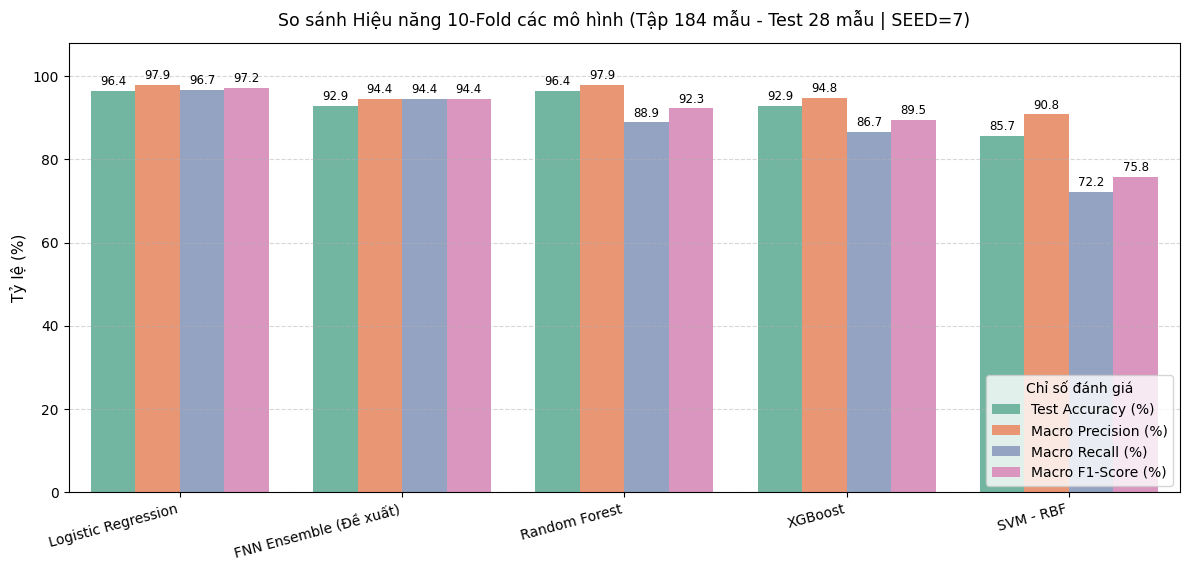

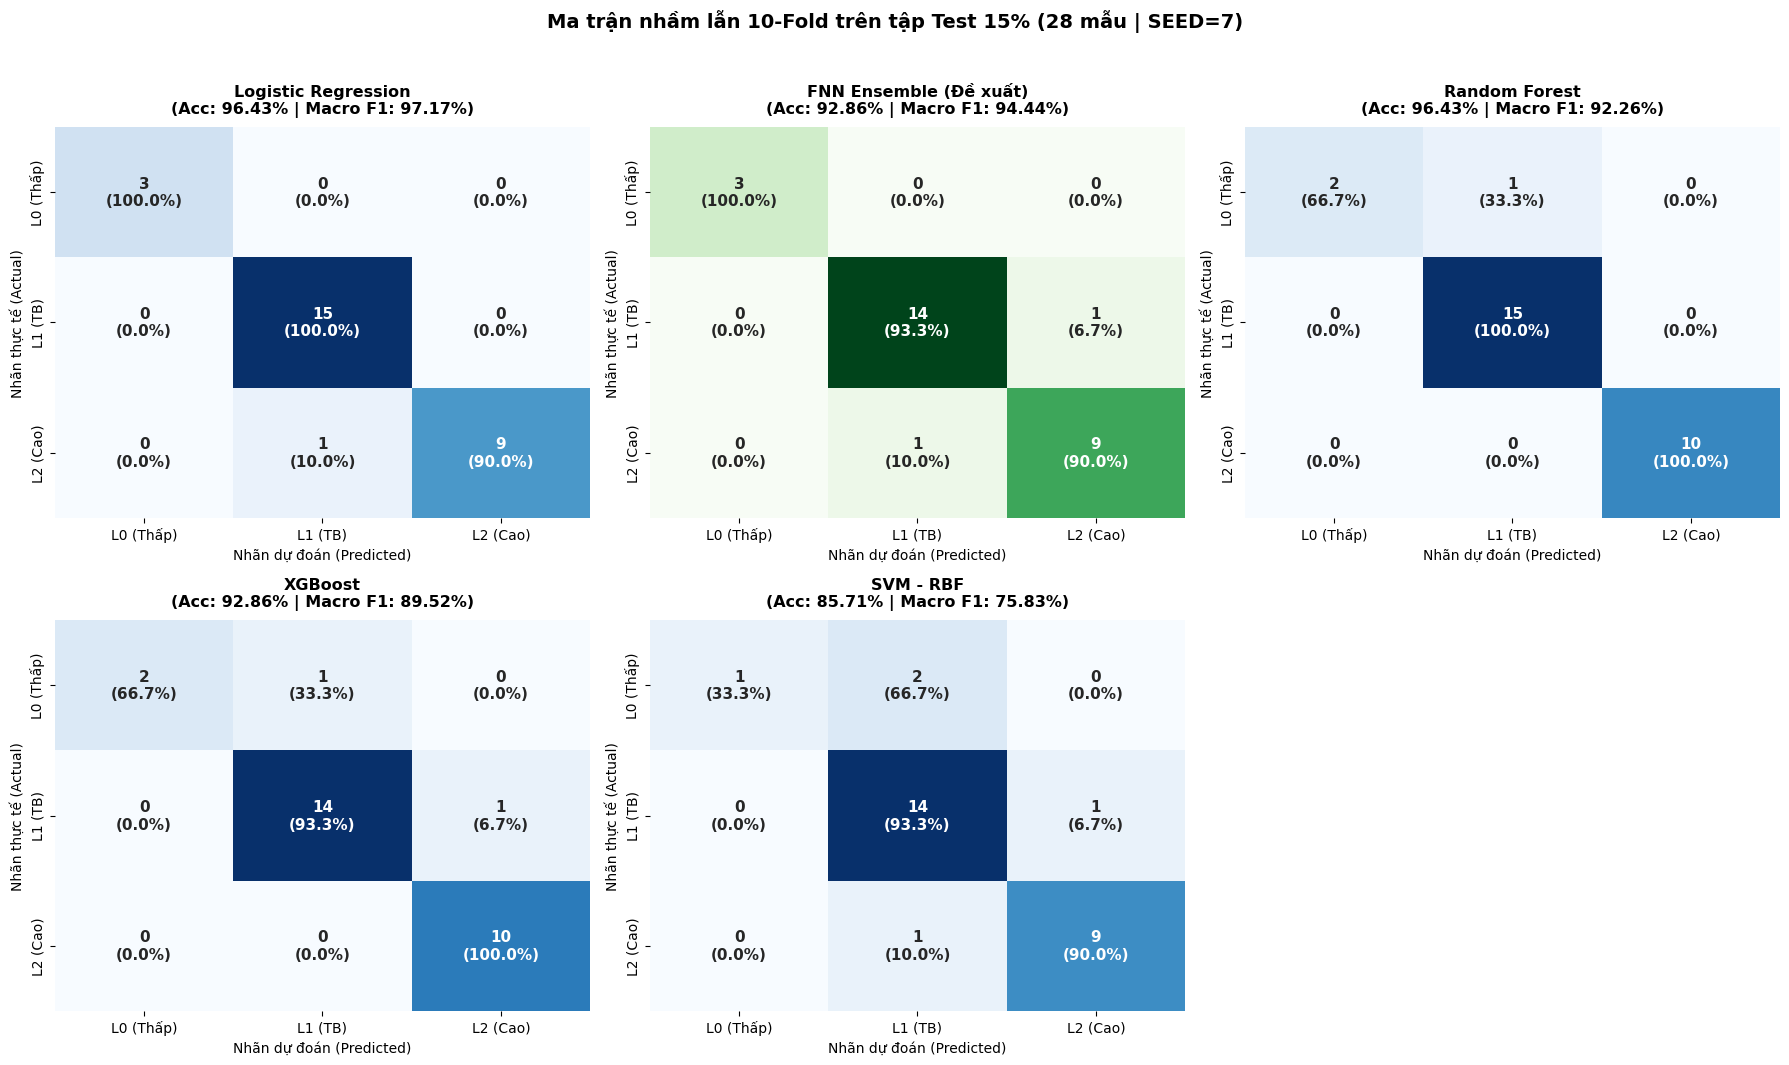

In [ ]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

# =========================================================================
# ĐẶT MÃ CHIA TẬP DỮ LIỆU KHỚP HOÀN TOÀN VỚI CELL 1 (FNN ENSEMBLE)
# =========================================================================
SPLIT_SEED = 7

if 'SAVED_SPLIT_SEED' in globals() and SAVED_SPLIT_SEED != SPLIT_SEED:
    raise ValueError(
        f"⚠️ Lệch SPLIT_SEED! Cell FNN đang dùng {SAVED_SPLIT_SEED}, "
        f"còn cell này đang đặt {SPLIT_SEED}. Hãy sửa cho giống nhau!"
    )

# =========================================================================
# 1. ĐỌC & TIỀN XỬ LÝ DỮ LIỆU ĐỒNG NHẤT VỚI CELL 1
# =========================================================================
df1 = pd.read_csv('drive/MyDrive/Training_data/sas-sv_data.csv')
df = df1.copy()
# Nếu Cell 1 đang chạy trên tập gộp 507 mẫu thì bỏ dấu # ở 2 dòng dưới:
# df2 = pd.read_csv('drive/MyDrive/Training_data/Smartphone_addiction_2.csv')
# df = pd.concat([df1, df2], ignore_index=True)

selected_features = ['tg_sudung_dt', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10']
valid_features = [col for col in selected_features if col in df.columns]

X_original = df[valid_features].copy()
Y = df['Level'].copy()

if Y.dtype == 'object':
    Y = Y.astype(str).str.strip().map({'L0': 0, 'L1': 1, 'L2': 2, '0': 0, '1': 1, '2': 2})
Y = pd.to_numeric(Y, errors='coerce')

valid_idx = Y.notna()
X_original = X_original[valid_idx].apply(pd.to_numeric, errors='coerce')
Y = Y[valid_idx].astype(int)

q_cols = [c for c in ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10'] if c in X_original.columns]
if len(q_cols) > 0:
    X_original['Q_mean'] = X_original[q_cols].mean(axis=1)
    X_original['Q_std']  = X_original[q_cols].std(axis=1)
    X_original['Q_max']  = X_original[q_cols].max(axis=1)

# =========================================================================
# 2. TÁCH TẬP TEST ĐỘC LẬP 15% KHỚP VỚI CELL 1
# =========================================================================
X_train_raw, X_test_raw, Y_train_raw, Y_test_raw = train_test_split(
    X_original, Y, test_size=0.15, random_state=SPLIT_SEED, stratify=Y
)

print(f"📌 Tổng dữ liệu: {len(Y)} mẫu | Train+Val (85%): {len(X_train_raw)} mẫu | Test (15%): {len(X_test_raw)} mẫu | SPLIT_SEED={SPLIT_SEED}")

# =========================================================================
# 3. KHỞI TẠO CÁC MÔ HÌNH CƠ SỞ & HUẤN LUYỆN 10-FOLD CROSS-VALIDATION
# =========================================================================
def get_baseline_models(seed):
    return {
        'Logistic Regression': LogisticRegression(max_iter=1000, random_state=seed),
        'SVM - RBF': SVC(kernel='rbf', C=1.0, probability=True, random_state=seed),
        'Random Forest': RandomForestClassifier(n_estimators=100, random_state=seed),
        'XGBoost': XGBClassifier(eval_metric='mlogloss', random_state=seed)
    }

n_splits = 10
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SPLIT_SEED)
output_classes = len(np.unique(Y))

model_names = list(get_baseline_models(SPLIT_SEED).keys())
test_preds_dict = {name: np.zeros((len(X_test_raw), output_classes)) for name in model_names}
oof_preds_dict = {name: np.zeros((len(X_train_raw), output_classes)) for name in model_names}

print(f"🚀 Đang huấn luyện {n_splits}-Fold cho các mô hình cơ sở...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train_raw, Y_train_raw), 1):
    X_tr = X_train_raw.iloc[train_idx].copy()
    Y_tr = Y_train_raw.iloc[train_idx].copy()

    X_val = X_train_raw.iloc[val_idx].copy()
    Y_val = Y_train_raw.iloc[val_idx].copy()

    X_te = X_test_raw.copy()

    # Bước A: Điền khuyết bằng median của tập Train Fold
    fold_medians = X_tr.median()
    X_tr = X_tr.fillna(fold_medians).fillna(0)
    X_val = X_val.fillna(fold_medians).fillna(0)
    X_te = X_te.fillna(fold_medians).fillna(0)

    # Bước B: Xử lý ngoại lai IQR cho 'tg_sudung_dt'
    feature_outlier = 'tg_sudung_dt'
    if feature_outlier in X_tr.columns:
        Q1 = X_tr[feature_outlier].quantile(0.25)
        Q3 = X_tr[feature_outlier].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        X_tr[feature_outlier] = np.clip(X_tr[feature_outlier], lower_bound, upper_bound)
        X_val[feature_outlier] = np.clip(X_val[feature_outlier], lower_bound, upper_bound)
        X_te[feature_outlier] = np.clip(X_te[feature_outlier], lower_bound, upper_bound)

    # Bước C: Chuẩn hóa StandardScaler trên dữ liệu thật TRƯỚC khi SMOTE
    scaler = StandardScaler()
    X_tr_scaled = scaler.fit_transform(X_tr)
    X_val_scaled = scaler.transform(X_val)
    X_te_scaled = scaler.transform(X_te)

    # Bước D: Cân bằng lớp bằng SMOTE
    sm = SMOTE(sampling_strategy='auto', random_state=SPLIT_SEED + fold)
    X_tr_res, Y_tr_res = sm.fit_resample(X_tr_scaled, Y_tr)

    # Huấn luyện và cộng dồn xác suất 10-Fold cho từng mô hình cơ sở
    models = get_baseline_models(SPLIT_SEED + fold)
    for name, clf in models.items():
        clf.fit(X_tr_res, Y_tr_res)
        oof_preds_dict[name][val_idx] = clf.predict_proba(X_val_scaled)
        test_preds_dict[name] += clf.predict_proba(X_te_scaled) / n_splits

print("✅ Hoàn tất huấn luyện 10-Fold cho tất cả mô hình cơ sở!\n")

# Ghép kết quả của FNN Ensemble (từ Cell 1) vào để so sánh trực tiếp
if 'test_predictions_folds' in globals() and len(test_predictions_folds) == len(X_test_raw):
    test_preds_dict['FNN Ensemble (Đề xuất)'] = test_predictions_folds
    if 'oof_predictions' in globals() and len(oof_predictions) == len(X_train_raw):
        oof_preds_dict['FNN Ensemble (Đề xuất)'] = oof_predictions
else:
    print("⚠️ Chưa tìm thấy `test_predictions_folds` từ Cell 1 hoặc khác kích thước tập Test. Hãy chạy Cell 1 trước!")

# =========================================================================
# 4. BẢNG SO SÁNH HIỆU NĂNG TOÀN DIỆN (OOF VAL & TEST 15%)
# =========================================================================
Y_true_test = Y_test_raw.values
Y_true_train = Y_train_raw.values
summary_rows = []

for name, pred_probs in test_preds_dict.items():
    y_pred = np.argmax(pred_probs, axis=1)
    f1_classes = f1_score(Y_true_test, y_pred, labels=[0, 1, 2], average=None, zero_division=0)

    oof_acc = (
        accuracy_score(Y_true_train, np.argmax(oof_preds_dict[name], axis=1)) * 100
        if name in oof_preds_dict else np.nan
    )

    summary_rows.append({
        'Mô hình': name,
        'OOF Val Acc (%)': round(oof_acc, 2),
        'Test Accuracy (%)': round(accuracy_score(Y_true_test, y_pred) * 100, 2),
        'Macro Precision (%)': round(precision_score(Y_true_test, y_pred, average='macro', zero_division=0) * 100, 2),
        'Macro Recall (%)': round(recall_score(Y_true_test, y_pred, average='macro', zero_division=0) * 100, 2),
        'Macro F1-Score (%)': round(f1_score(Y_true_test, y_pred, average='macro', zero_division=0) * 100, 2),
        'Weighted F1 (%)': round(f1_score(Y_true_test, y_pred, average='weighted', zero_division=0) * 100, 2),
        'F1 L0 (%)': round(f1_classes[0] * 100, 2),
        'F1 L1 (%)': round(f1_classes[1] * 100, 2),
        'F1 L2 (%)': round(f1_classes[2] * 100, 2),
    })

df_compare = pd.DataFrame(summary_rows).sort_values(by='Macro F1-Score (%)', ascending=False).reset_index(drop=True)

print("=" * 112)
print(f"📊 BẢNG SO SÁNH 10-FOLD ENSEMBLE GIỮA CÁC MÔ HÌNH (TẬP {len(Y)} MẪU | TEST {len(Y_true_test)} MẪU | SEED={SPLIT_SEED})")
print("=" * 112)
print(df_compare.to_string(index=False))
print("=" * 112)

# =========================================================================
# 5. BIỂU ĐỒ 1: SO SÁNH ACCURACY, PRECISION, RECALL & F1-SCORE
# =========================================================================
df_melt = df_compare.melt(
    id_vars='Mô hình',
    value_vars=['Test Accuracy (%)', 'Macro Precision (%)', 'Macro Recall (%)', 'Macro F1-Score (%)'],
    var_name='Chỉ số',
    value_name='Điểm số (%)'
)

plt.figure(figsize=(12, 5.8))
ax = sns.barplot(data=df_melt, x='Mô hình', y='Điểm số (%)', hue='Chỉ số', palette='Set2')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', fontsize=8.5, padding=2)

plt.title(f'So sánh Hiệu năng 10-Fold các mô hình (Tập {len(Y)} mẫu - Test {len(Y_true_test)} mẫu | SEED={SPLIT_SEED})', fontsize=12.5, pad=12)
plt.ylabel('Tỷ lệ (%)', fontsize=11)
plt.xlabel('')
plt.ylim(0, 108)
plt.xticks(rotation=15, ha='right')
plt.legend(title='Chỉ số đánh giá', loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('So_sanh_10Fold_Metrics.png', dpi=300, bbox_inches='tight')
plt.show()

# =========================================================================
# 6. BIỂU ĐỒ 2: MA TRẬN NHẦM LẪN (CONFUSION MATRIX) CỦA TẤT CẢ MÔ HÌNH
# =========================================================================
ordered_models = df_compare['Mô hình'].tolist()
n_models = len(ordered_models)
ncols = 3
nrows = math.ceil(n_models / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 5.2 * nrows))
axes = np.array(axes).reshape(-1)
short_labels = ['L0 (Thấp)', 'L1 (TB)', 'L2 (Cao)']

for idx, name in enumerate(ordered_models):
    ax_cm = axes[idx]
    y_pred = np.argmax(test_preds_dict[name], axis=1)

    cm_count = confusion_matrix(Y_true_test, y_pred, labels=[0, 1, 2])
    cm_sum = cm_count.sum(axis=1)[:, np.newaxis]
    cm_percent = np.divide(cm_count, cm_sum, out=np.zeros_like(cm_count, dtype=float), where=cm_sum != 0) * 100

    annot_labels = np.empty_like(cm_count, dtype=object)
    for i in range(cm_count.shape[0]):
        for j in range(cm_count.shape[1]):
            annot_labels[i, j] = f"{cm_count[i, j]}\n({cm_percent[i, j]:.1f}%)"

    cmap_color = 'Greens' if 'FNN' in name else 'Blues'
    acc_val = accuracy_score(Y_true_test, y_pred) * 100
    f1_val = f1_score(Y_true_test, y_pred, average='macro', zero_division=0) * 100

    sns.heatmap(
        cm_count,
        annot=annot_labels,
        fmt='',
        cmap=cmap_color,
        xticklabels=short_labels,
        yticklabels=short_labels,
        annot_kws={"size": 11, "weight": "bold"},
        cbar=False,
        ax=ax_cm
    )
    ax_cm.set_title(f"{name}\n(Acc: {acc_val:.2f}% | Macro F1: {f1_val:.2f}%)", fontsize=11.5, fontweight='bold', pad=10)
    ax_cm.set_xlabel('Nhãn dự đoán (Predicted)', fontsize=10)
    ax_cm.set_ylabel('Nhãn thực tế (Actual)', fontsize=10)

for empty_idx in range(n_models, len(axes)):
    axes[empty_idx].axis('off')

plt.suptitle(f'Ma trận nhầm lẫn 10-Fold trên tập Test 15% ({len(Y_true_test)} mẫu | SEED={SPLIT_SEED})', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('Confusion_Matrix_10Fold_All.png', dpi=300, bbox_inches='tight')
plt.show()